# Phase 3 · Machine learning

## Data and preprocessing

This notebook starts from the dataset files in `141/` and uses the cleaning and predictors from `phase_02.ipynb`, sections 2.1 and 2.3. The original 80/20 unit-level split is reproduced before cleaning. The validation folds also keep all readings from an APU together.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OrdinalEncoder, RobustScaler

SEED = 42
data_dir = Path("141")
readings = pd.read_csv(data_dir / "readings.csv", sep="	")
units = pd.read_csv(data_dir / "units.csv")


sensor_cols = ["current_motor", "dp_filter", "oilTemperature", "reservoir_pressure",
               "vibration_rms", "Flowmeter", "temp_bearing", "dewpointDischarge", "auxCurrent"]

In [2]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
train_index, test_index = next(splitter.split(readings, groups=readings['unitId']))

train_readings = readings.iloc[train_index].copy()
test_readings = readings.iloc[test_index].copy()
assert set(train_readings['unitId']).isdisjoint(test_readings['unitId'])
assert len(train_readings) + len(test_readings) == len(readings)

split_summary = pd.DataFrame([
    {'set': name, 'rows': len(frame), 'units': frame['unitId'].nunique(),
     'row_percent': 100 * len(frame) / len(readings)}
    for name, frame in [('Training', train_readings), ('Test (reserved)', test_readings)]
])
display(split_summary.round(2))

,set,rows,units,row_percent
0,Training,12097,1699,80.22
1,Test (reserved),2983,425,19.78


In [3]:
def parse_dates(values):
    parsed = pd.Series(pd.NaT, index=values.index, dtype="datetime64[ns]")
    for fmt in ["%Y-%m-%d", "%m/%d/%Y, %H:%M:%S", "%d %b %Y", "%Y/%m/%d"]:
        parsed = parsed.fillna(pd.to_datetime(values.str.strip(), format=fmt, errors="coerce"))
    return parsed

metadata_cols = ['model_code', 'fleet_code', 'class_duty', 'commissionYear']

def prepare_readings(frame, unit_metadata):
    prepared = frame.copy()
    prepared['unitId'] = prepared['unitId'].str.extract(r'^U(\d{5})$', expand=False).astype(int)
    prepared['tsCycle'] = parse_dates(prepared['tsCycle'])
    if prepared['tsCycle'].isna().any():
        raise ValueError('Some cycle dates do not match the documented formats.')
    before = len(prepared)
    prepared = prepared.drop_duplicates()
    duplicate_rows = before - len(prepared)
    prepared = prepared.merge(unit_metadata[['unitId'] + metadata_cols], on='unitId',
                              how='left', validate='many_to_one', indicator='unit_match')
    invalid = prepared['commissionYear'].gt(prepared['tsCycle'].dt.year)
    chronology_rows = int(invalid.sum())
    prepared = prepared.loc[~invalid].copy()
    audit = {'rows_before_cleaning': before,
             'exact_duplicates_removed': duplicate_rows,
             'chronology_conflicts_removed': chronology_rows,
             'remaining_rows': len(prepared),
             'rows_without_unit_metadata': int(prepared['unit_match'].eq('left_only').sum())}
    return prepared, audit

training, cleaning_audit = prepare_readings(train_readings, units)
assert training['failure'].isin([0, 1]).all()
display(pd.Series(cleaning_audit, name='rows').to_frame())

,rows
rows_before_cleaning,12097
exact_duplicates_removed,175
chronology_conflicts_removed,247
remaining_rows,11675
rows_without_unit_metadata,115


The pipeline replaces the Phase 2 sentinel values with missing values, imputes numeric predictors with medians, applies robust scaling, and ordinal-encodes duty as light, normal, or heavy. Missing and unseen duty values use code −1. Numeric extremes are retained. Each training fold fits its own imputer and scaler. The target, unit ID, and timestamp are excluded from the model inputs.

The 11 predictors carry forward Phase 2 feature selection, which used development data. Cross-validation within that same development set is suitable for comparing candidates. An independent estimate requires the reserved set.

In [4]:
duty_aliases = {'light': 'light', 'l': 'light', '1': 'light',
                'normal': 'normal', 'n': 'normal', 'med': 'normal', '2': 'normal',
                'heavy': 'heavy', 'h': 'heavy', '3': 'heavy'}

duty_order = ['light', 'normal', 'heavy']
numeric_cols = sensor_cols + ['commissionYear']
feature_cols = numeric_cols + ['class_duty']

def normalize_predictors(frame):
    normalized = frame.copy()
    normalized['oilTemperature'] = normalized['oilTemperature'].replace(-999, np.nan)
    normalized['current_motor'] = normalized['current_motor'].replace(99, np.nan)
    duty = normalized['class_duty'].astype('string').str.strip().str.lower()
    duty = duty.replace(duty_aliases)
    normalized['class_duty'] = duty.astype(object).where(duty.notna(), np.nan)
    return normalized


cleaner = FunctionTransformer(normalize_predictors)

numeric_branch = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler())
])

duty_branch = OrdinalEncoder(categories=[duty_order + [np.nan]],
                             handle_unknown='use_encoded_value', unknown_value=-1,
                             encoded_missing_value=-1, dtype=np.int64)

column_transformer = ColumnTransformer([
    ('numeric', numeric_branch, numeric_cols),        
    ('duty', duty_branch, ['class_duty'])
], remainder='drop', verbose_feature_names_out=False)

preprocessor = Pipeline([
    ('clean', cleaner),
    ('encode_and_scale', column_transformer)
])

In [5]:
X_train = training[feature_cols]
y_train = training['failure'].astype(int)
train_groups = training['unitId']

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_splits = list(cv.split(X_train, y_train, groups=train_groups))
validation_rows = np.concatenate([valid_idx for _, valid_idx in cv_splits])
assert np.array_equal(np.sort(validation_rows), np.arange(len(X_train)))

fold_summary = []
for fold, (fit_idx, valid_idx) in enumerate(cv_splits, start=1):
    fit_groups = set(train_groups.iloc[fit_idx])
    valid_groups = set(train_groups.iloc[valid_idx])
    assert fit_groups.isdisjoint(valid_groups)
    assert y_train.iloc[fit_idx].nunique() == y_train.iloc[valid_idx].nunique() == 2
    fold_summary.append({
        'Fold': fold,
        'Training units': len(fit_groups),
        'Validation units': len(valid_groups),
        'Validation readings': len(valid_idx),
        'Validation failures': int(y_train.iloc[valid_idx].sum()),
        'Validation failure rate': y_train.iloc[valid_idx].mean(),
    })
print(f"Development set: {len(y_train):,} readings, {y_train.sum():,} failures "
      f"({y_train.mean():.2%})")
display(pd.DataFrame(fold_summary).set_index('Fold').round(3))

Development set: 11,675 readings, 1,473 failures (12.62%)


,Training units,Validation units,Validation readings,Validation failures,Validation failure rate
Fold,,,,,
1,1338,330,2337,296,0.127
2,1325,343,2335,295,0.126
3,1338,330,2335,294,0.126
4,1338,330,2333,294,0.126
5,1333,335,2335,294,0.126


## 3.1 A simple classifier based on relationships in the data

### A. Implement ID3

Iterative Dichotomizer 3 (ID3) chooses the predictor that gives the largest information gain at each node. For a split on feature $A$, the information gain is the parent entropy ($H(S)$) minus the weighted mean of the child entropies ($H(S_v)$).

$$
H(S)=\sum_{c\in\{0,1\}} -p_c\log_2 p_c,
\qquad
IG(S,A)=H(S)-\sum_v \frac{|S_v|}{|S|}H(S_v).
$$

Each observed category gets its own branch, and a feature can be used once along a path. A leaf predicts its majority class. When a category has no branch at prediction time, the current node supplies its majority class and observed failure proportion. The root counts as depth 1, so a root with leaves has depth 2. 

ID3 takes categorical inputs. We discretize each numeric predictor into up to five quantile bins, keeping the encoded duty categories as they are. Quantiles are fitted inside each training fold after Phase 2 preprocessing. Tied quantiles can yield fewer distinct bins. For `commissionYear`, we keep scikit-learn's automatic merging of tied quantiles and suppress only the resulting narrow-bin warning for that column. We use equal-frequency bins to give each interval similar training support when the readings have distinct values.

In [6]:
from dataclasses import dataclass, field

from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.preprocessing import KBinsDiscretizer
from sklearn.utils.validation import check_is_fitted, validate_data


def binary_entropy(labels):
    counts = np.bincount(labels, minlength=2)
    proportions = counts[counts > 0] / len(labels)
    return -np.sum(proportions * np.log2(proportions))


@dataclass
class ID3Node:
    failure_rate: float
    feature: int | None = None
    children: dict = field(default_factory=dict)

    def depth(self):
        return 1 + max((child.depth() for child in self.children.values()), default=0)

    def leaf_count(self):
        return sum(child.leaf_count() for child in self.children.values()) or 1


class ID3Classifier(ClassifierMixin, BaseEstimator):
    def __init__(self, max_depth=None, min_samples_leaf=1):
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf

    def fit(self, X, y):
        X, y = validate_data(self, X, y)
        self.classes_ = np.unique(y)
        if not np.array_equal(self.classes_, [0, 1]):
            raise ValueError("ID3Classifier requires both binary labels, 0 and 1.")
        self.tree_ = self._grow(X, y.astype(int), tuple(range(X.shape[1])), level=1)
        self.depth_ = self.tree_.depth()
        self.leaf_count_ = self.tree_.leaf_count()
        return self

    def _grow(self, X, y, available, level):
        node = ID3Node(failure_rate=float(y.mean()))
        if (node.failure_rate in (0, 1)
                or not available
                or (self.max_depth is not None and level >= self.max_depth)):
            return node

        parent_entropy = binary_entropy(y)
        best_gain = 1e-12
        best_parts = {}
        for feature in available:
            values = X[:, feature]
            parts = {value: np.flatnonzero(values == value) for value in np.unique(values)}
            if len(parts) < 2 or min(map(len, parts.values())) < self.min_samples_leaf:
                continue
            weighted_entropy = sum(
                len(rows) / len(y) * binary_entropy(y[rows]) for rows in parts.values()
            )
            gain = parent_entropy - weighted_entropy
            if gain > best_gain:
                best_gain = gain
                node.feature = feature
                best_parts = parts

        if best_parts:
            remaining = tuple(feature for feature in available if feature != node.feature)
            node.children = {
                value: self._grow(X[rows], y[rows], remaining, level + 1)
                for value, rows in best_parts.items()
            }
        return node

    def _failure_rate(self, row):
        node = self.tree_
        while node.children:
            child = node.children.get(row[node.feature])
            if child is None:
                break
            node = child
        return node.failure_rate

    def predict_proba(self, X):
        check_is_fitted(self, "tree_")
        X = validate_data(self, X, reset=False)
        failure_rates = np.fromiter(map(self._failure_rate, X), dtype=float, count=len(X))
        return np.column_stack((1 - failure_rates, failure_rates))

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(axis=1)]


# Check a perfect split and the fallback for a previously unseen category.
example = ID3Classifier().fit([[0], [0], [1], [1]], [0, 0, 1, 1])
assert example.depth_ == 2
assert example.predict([[0], [1], [2]]).tolist() == [0, 1, 0]
assert np.allclose(example.predict_proba([[2]])[0], [0.5, 0.5])

In [7]:
import warnings


class CommissionYearBinner(KBinsDiscretizer):
    def fit(self, X, y=None, sample_weight=None):
        # Tied year quantiles can collapse. Keep scikit-learn's merged bins.
        with warnings.catch_warnings():
            warnings.filterwarnings(
                "ignore",
                message=r"^Bins whose width are too small .* in feature 0 are removed\.",
                category=UserWarning,
                module=r"^sklearn\.preprocessing\._discretization$",
            )
            return super().fit(X, y, sample_weight=sample_weight)


def make_id3(max_depth=None, min_samples_leaf=1):
    binning = dict(n_bins=5, encode="ordinal", strategy="quantile",
                   subsample=None, quantile_method="averaged_inverted_cdf")
    year_index = numeric_cols.index("commissionYear")
    discretizer = ColumnTransformer([
        ("sensor_bins", KBinsDiscretizer(**binning), list(range(year_index))),
        ("year_bins", CommissionYearBinner(**binning), [year_index]),
    ], remainder="passthrough")
    return Pipeline([
        ("preprocess", clone(preprocessor)),
        ("discretize", discretizer),
        ("classifier", ID3Classifier(max_depth=max_depth, min_samples_leaf=min_samples_leaf)),
    ])

### B–C. Evaluate ID3 and check for overfitting

Each of the five grouped folds evaluates the same metrics on its training and validation readings. Accuracy counts the fraction classified correctly, precision is the fraction of predicted failures that are actual failures, and recall is the fraction of actual failures detected. Class 1 is the positive class. A rule that always predicts no failure would reach about 87% accuracy on these data with zero failure recall.

We report F1, the harmonic mean of failure precision and recall, and average precision (AP), which summarizes precision and recall across score thresholds. We diagnose overfitting by looking for a training–validation gap, especially in AP, alongside the number of leaves. To reduce variance, we compare an unrestricted tree with trees limited to two through five levels and at least 30 training readings per child. We select the shallowest constrained tree whose mean validation AP is within one standard error of the best constrained mean. This is a simplicity rule for model selection. Fold standard errors are descriptive because training folds overlap.

In [8]:
from sklearn.metrics import (
    accuracy_score, average_precision_score, confusion_matrix, f1_score,
    precision_score, recall_score,
)

metric_names = ["Accuracy", "Precision", "Recall", "F1", "AP"]


def classification_metrics(y_true, y_pred, failure_score):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "AP": average_precision_score(y_true, failure_score),
    }


def evaluate_folds(name, pipeline):
    results = []
    for fold, (fit_idx, valid_idx) in enumerate(cv_splits, start=1):
        fitted = clone(pipeline).fit(X_train.iloc[fit_idx], y_train.iloc[fit_idx])
        model = fitted.named_steps["classifier"]
        for split, indices in [("Training", fit_idx), ("Validation", valid_idx)]:
            X_fold, y_fold = X_train.iloc[indices], y_train.iloc[indices]
            results.append({
                "Model": name,
                "Fold": fold,
                "Split": split,
                **classification_metrics(y_fold, fitted.predict(X_fold),
                                         fitted.predict_proba(X_fold)[:, 1]),
                "Depth (levels)": getattr(model, "depth_", np.nan),
                "Leaves": getattr(model, "leaf_count_", np.nan),
            })
    return pd.DataFrame(results)


unrestricted = "ID3 unrestricted"
id3_models = {unrestricted: make_id3()}
id3_models.update({f"ID3 {levels} levels": make_id3(max_depth=levels, min_samples_leaf=30)
                   for levels in range(2, 6)})
id3_cv = pd.concat([evaluate_folds(name, model) for name, model in id3_models.items()],
                   ignore_index=True)

id3_cv_means = id3_cv.groupby(["Model", "Split"], sort=False)[metric_names].mean()
id3_cv_ap = id3_cv_means["AP"].unstack("Split").rename(
    columns={"Training": "Train AP", "Validation": "Validation AP"})
id3_cv_ap["AP gap"] = id3_cv_ap["Train AP"] - id3_cv_ap["Validation AP"]
id3_validation = id3_cv[id3_cv["Split"].eq("Validation")]
id3_cv_ap["Validation AP SE"] = id3_validation.groupby("Model")["AP"].sem()
id3_cv_ap["Mean leaves"] = id3_validation.groupby("Model")["Leaves"].mean()

constrained = id3_cv_ap.drop(index=unrestricted)
best_constrained = constrained["Validation AP"].idxmax()
cutoff = (constrained.at[best_constrained, "Validation AP"]
          - constrained.at[best_constrained, "Validation AP SE"])
selected_id3 = constrained.index[constrained["Validation AP"].ge(cutoff)][0]
assert id3_validation.loc[id3_validation["Model"].eq(selected_id3),
                          "Depth (levels)"].min() >= 2

display(id3_cv_ap.round(3))
display(id3_cv_means.loc[[unrestricted, selected_id3]].round(3))
print(f"Selected {selected_id3} for comparison. Validation AP cutoff = {cutoff:.3f}.")

Selected ID3 3 levels for comparison. Validation AP cutoff = 0.211.


Split,Train AP,Validation AP,AP gap,Validation AP SE,Mean leaves
Model,,,,,
ID3 unrestricted,1.000,0.151,0.849,0.005,3104.4
ID3 2 levels,0.171,0.168,0.003,0.005,4.8
ID3 3 levels,0.219,0.211,0.008,0.004,22.6
ID3 4 levels,0.278,0.217,0.062,0.006,111.0
ID3 5 levels,0.281,0.216,0.066,0.006,133.0


Accuracy  Precision  Recall     F1     AP
Model            Split                                                
ID3 unrestricted Training       1.000      1.000   0.999  0.999  1.000
                 Validation     0.798      0.213   0.221  0.216  0.151
ID3 3 levels     Training       0.874      0.000   0.000  0.000  0.219
                 Validation     0.874      0.000   0.000  0.000  0.211

The unrestricted tree has about 3,104 leaves per fold. Its training AP is 1.000, but validation AP falls to 0.151. The training accuracy is nearly 100% and the validation accuracy falls to 79.8%. Both gaps indicate overfitting.

The selected tree has three levels, including the root, with at least 30 training readings per child. It has about 23 leaves per fold. Its training and validation AP are 0.219 and 0.211, respectively. The smaller gap and higher validation AP support the depth and leaf-size limits. Its majority-class rule detects no failures in validation, so its 87.4% accuracy matches the always-no-failure baseline. Section 3.2 evaluates whether a lower threshold on its leaf failure proportions makes the scores more useful.

## 3.2 Training and evaluating machine learning classifiers

### A–C. Compare three classifiers

We compare ID3 with two scikit-learn pipelines, CART decision trees and logistic regression, on the same grouped validation folds. The CART decision tree uses Gini impurity and binary splits on numeric thresholds. A preset three-split depth limit keeps the learned rules readable. Logistic regression uses an L2 penalty with the default regularization strength. Its linear log-odds serve as a non-tree reference.

Both scikit-learn models use the same Phase 2 preprocessing as ID3. They use continuous numeric values without ID3's quantile binning. We use the usual class decision for each estimator and keep the observed class proportions.

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

cart_name = "CART decision tree"
logistic_name = "Logistic regression"
models = {
    selected_id3: id3_models[selected_id3],
    cart_name: Pipeline([
        ("preprocess", clone(preprocessor)),
        ("classifier", DecisionTreeClassifier(max_depth=3, random_state=SEED)),
    ]),
    logistic_name: Pipeline([
        ("preprocess", clone(preprocessor)),
        ("classifier", LogisticRegression(max_iter=1000, random_state=SEED)),
    ]),
}

model_cv = pd.concat([
    id3_cv.loc[id3_cv["Model"].eq(selected_id3)],
    evaluate_folds(cart_name, models[cart_name]),
    evaluate_folds(logistic_name, models[logistic_name]),
], ignore_index=True)
validation_metrics = model_cv.loc[model_cv["Split"].eq("Validation")]
validation_summary = validation_metrics.groupby("Model", sort=False)[metric_names].agg(["mean", "std"])
display(validation_summary.round(3))

Accuracy        Precision        Recall            F1            AP       
                        mean    std      mean    std   mean    std   mean    std   mean    std
Model                                                                                         
ID3 3 levels           0.874  0.000     0.000  0.000  0.000  0.000  0.000  0.000  0.211  0.010
CART decision tree     0.878  0.003     0.552  0.041  0.140  0.088  0.212  0.128  0.256  0.028
Logistic regression    0.873  0.004     0.510  0.187  0.049  0.019  0.088  0.031  0.326  0.026

#### Choosing a threshold using development data

The validation scores above use the models' default class decisions. We choose the threshold that maximizes failure F1 over the out-of-fold scores, breaking ties in favor of the higher threshold. F1 balances precision and recall for this comparison. The threshold selection uses the development folds, so the reserved APUs provide the evaluation of the resulting rules.

In [10]:
from sklearn.metrics import precision_recall_curve
from sklearn.model_selection import cross_val_predict

alert_thresholds = {}
for name, model in models.items():
    out_of_fold = cross_val_predict(
        model, X_train, y_train, cv=cv_splits, method="predict_proba"
    )[:, 1]
    precision, recall, thresholds = precision_recall_curve(y_train, out_of_fold)
    precision, recall = precision[:-1], recall[:-1]
    f1 = np.divide(2 * precision * recall, precision + recall,
                   out=np.zeros_like(precision), where=(precision + recall) > 0)
    best_index = np.flatnonzero(f1 == f1.max())[-1]
    alert_thresholds[name] = float(thresholds[best_index])

display(pd.Series(alert_thresholds, name="Failure alert threshold").to_frame().round(4))

,Failure alert threshold
ID3 3 levels,0.1667
CART decision tree,0.1769
Logistic regression,0.2066


### D. Visualize the decision rules

Each node shows the rule applied to a preprocessed reading. Follow the left branch when the condition is true. Continuous thresholds are in robust-scaled units. Duty codes are −1 for missing or unseen, 0 for light, 1 for normal, and 2 for heavy. The node's class is its majority training label. The root uses `dp_filter`. Later splits use `dp_filter`, `class_duty`, and `current_motor`.

Final ID3 depth: 3 levels, including the root. Leaves: 25.


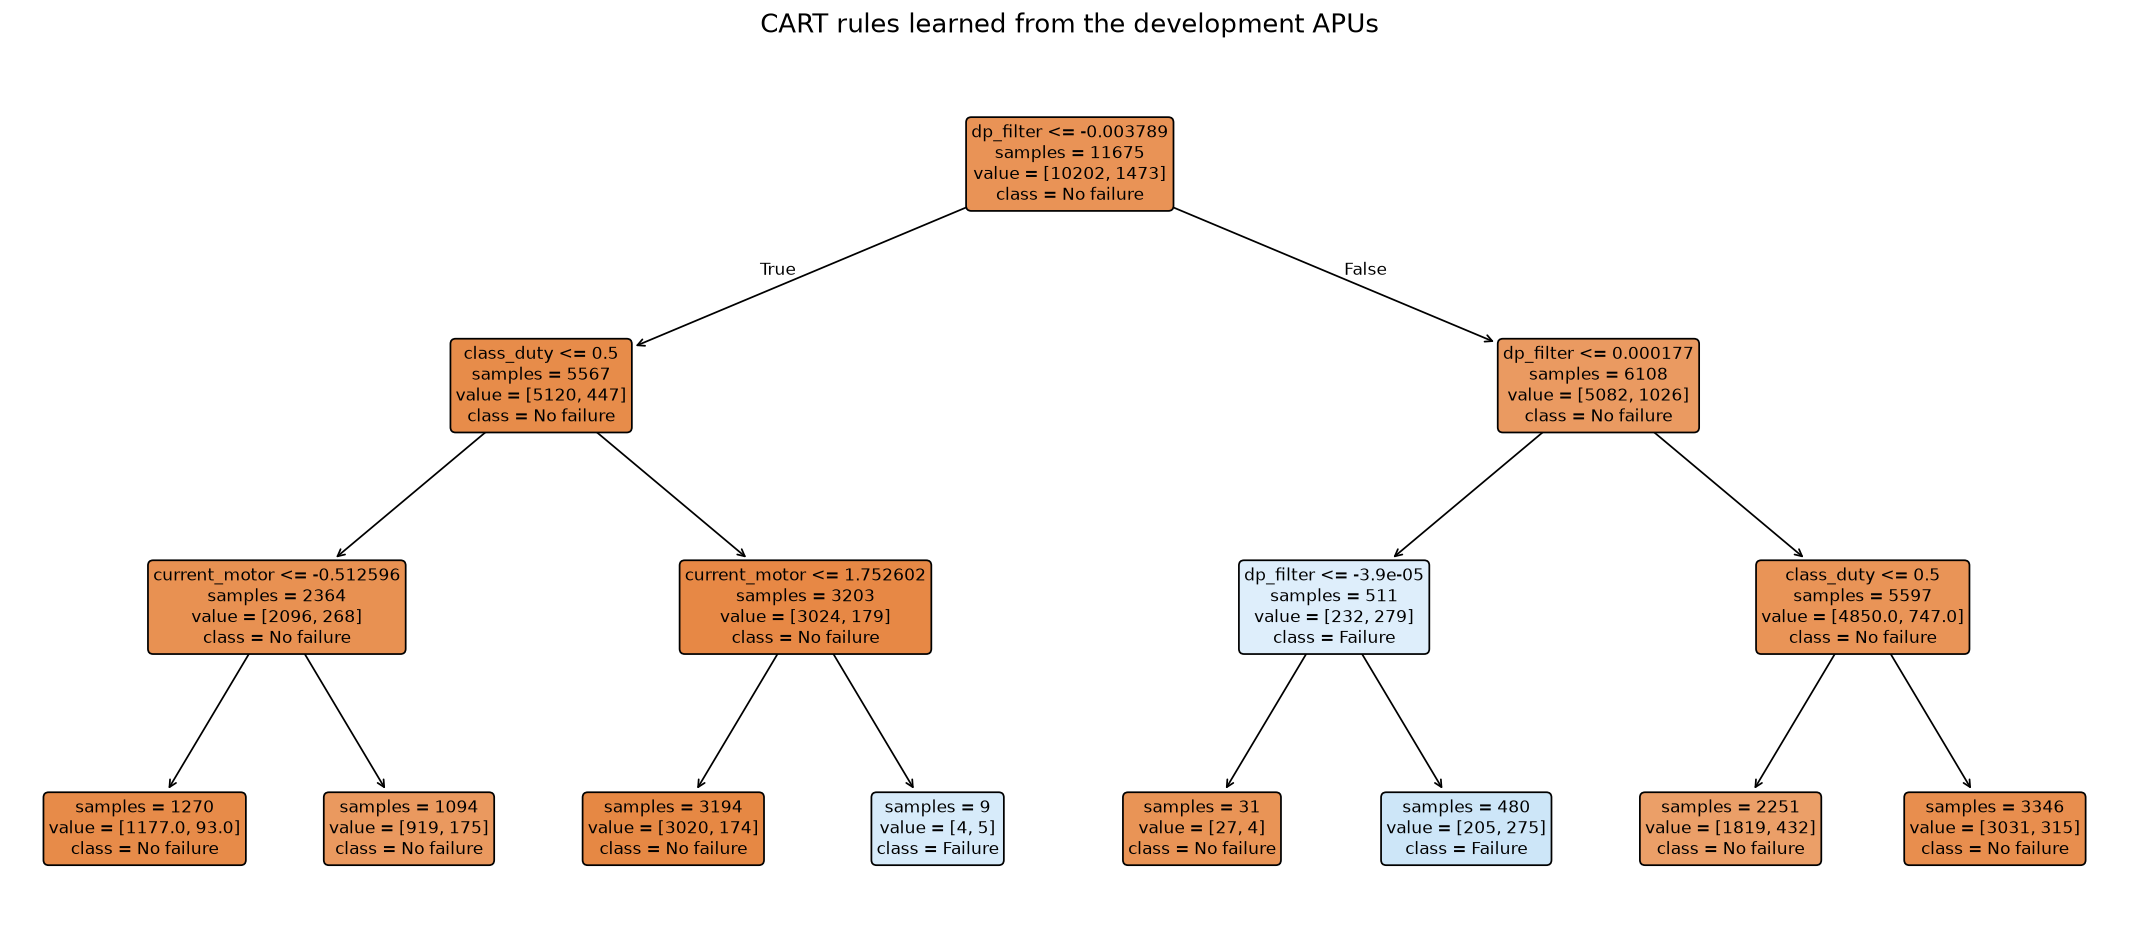

In [11]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

fitted_models = {name: clone(model).fit(X_train, y_train) for name, model in models.items()}
fitted_id3 = fitted_models[selected_id3].named_steps["classifier"]
assert fitted_id3.depth_ >= 2
print(f"Final ID3 depth: {fitted_id3.depth_} levels, including the root. "
      f"Leaves: {fitted_id3.leaf_count_}.")

fig, ax = plt.subplots(figsize=(17, 7.5), layout="constrained")
plot_tree(fitted_models[cart_name].named_steps["classifier"],
          feature_names=feature_cols, class_names=["No failure", "Failure"],
          filled=True, rounded=True, impurity=False, precision=6, fontsize=10, ax=ax)
ax.set_title("CART rules learned from the development APUs", fontsize=15, pad=12)
display(fig)
plt.close(fig)

### E. Evaluate on the reserved APUs

We now apply the fixed Phase 2 row-cleaning rules to the reserved partition and score the three fitted pipelines. The first table uses the default class decisions. The second uses the alert thresholds chosen on development data. AP depends on the ranking of failure scores and is identical across the two tables. All imputation, scaling, binning, and model parameters come from the development data. Each metric pools readings across the held-out APUs. These scores measure classification of the recorded `failure` label on unseen units. The experiment does not measure how far ahead an alert could predict a future failure.

In [12]:
test, test_audit = prepare_readings(test_readings, units)
assert set(training["unitId"]).isdisjoint(test["unitId"])
assert test["failure"].isin([0, 1]).all()
X_test = test[feature_cols]
y_test = test["failure"].astype(int)

holdout_rows = []
for name, fitted in fitted_models.items():
    failure_score = fitted.predict_proba(X_test)[:, 1]
    decisions = {
        "Default": fitted.predict(X_test),
        "Alert threshold": (failure_score >= alert_thresholds[name]).astype(int),
    }
    for rule, prediction in decisions.items():
        tn, fp, fn, tp = confusion_matrix(y_test, prediction, labels=[0, 1]).ravel()
        assert tn + fp + fn + tp == len(y_test)
        holdout_rows.append({
            "Model": name,
            "Rule": rule,
            **classification_metrics(y_test, prediction, failure_score),
            "False positives": fp,
            "Missed failures": fn,
            "Detected failures": tp,
        })

holdout_results = pd.DataFrame(holdout_rows).set_index(["Rule", "Model"])
print(f"Holdout: {len(y_test):,} eligible readings from {test['unitId'].nunique():,} APUs. "
      f"{y_test.sum():,} failures ({y_test.mean():.2%}).")
print(f"Always predicting no failure: accuracy {1 - y_test.mean():.3f}, recall 0.")
display(holdout_results.loc["Default"].round(3))
display(holdout_results.loc["Alert threshold"].round(3))

Holdout: 2,902 eligible readings from 421 APUs. 356 failures (12.27%).
Always predicting no failure: accuracy 0.877, recall 0.


,Accuracy,Precision,Recall,F1,AP,False positives,Missed failures,Detected failures
Model,,,,,,,,
ID3 3 levels,0.877,0.000,0.000,0.000,0.181,0,356,0
CART decision tree,0.879,0.529,0.154,0.239,0.247,49,301,55
Logistic regression,0.878,0.522,0.067,0.119,0.311,22,332,24


,Accuracy,Precision,Recall,F1,AP,False positives,Missed failures,Detected failures
Model,,,,,,,,
ID3 3 levels,0.749,0.194,0.331,0.245,0.181,491,238,118
CART decision tree,0.763,0.247,0.455,0.320,0.247,495,194,162
Logistic regression,0.820,0.326,0.441,0.375,0.311,324,199,157


All three accuracies are close to the 87.7% majority baseline. ID3 flags zero failures, CART detects 55 of 356 failures, and logistic regression detects 24. Precision is reported as zero when a rule issues no positive predictions.

For development-selected thresholds. ID3 detects 118 failures (33.1% recall), with 19.4% precision. CART detects 162 (45.5% recall) with 495 false alerts. Logistic regression detects 157 (44.1% recall) with 324 false alerts, reaching 32.6% precision. It has the highest holdout F1 (0.375) and AP (0.311) of the configurations. CART finds five more failures at the cost of 171 additional false alerts.

## Experiment s vazenymi failures nizsie

In [13]:
# Logistic regression with class weights, using the existing grouped folds
from sklearn.metrics import roc_curve

weight_options = {
    "Unweighted": None,
    "Failure weight 3x": {0: 1, 1: 3},
    "Balanced": "balanced",
}
weighted_models = {
    name: clone(models[logistic_name]).set_params(classifier__class_weight=weight)
    for name, weight in weight_options.items()
}

weight_fold_ap = {}
weight_thresholds = {}
for name, model in weighted_models.items():
    scores = cross_val_predict(
        model, X_train, y_train, cv=cv_splits, method="predict_proba"
    )[:, 1]
    weight_fold_ap[name] = [
        average_precision_score(y_train.iloc[valid_idx], scores[valid_idx])
        for _, valid_idx in cv_splits
    ]
    precision, recall, thresholds = precision_recall_curve(y_train, scores)
    precision, recall = precision[:-1], recall[:-1]
    f1 = np.divide(2 * precision * recall, precision + recall,
                   out=np.zeros_like(precision), where=(precision + recall) > 0)
    best_index = np.flatnonzero(f1 == f1.max())[-1]
    weight_thresholds[name] = float(thresholds[best_index])

weight_cv_ap = pd.DataFrame(weight_fold_ap, index=pd.Index(range(1, 6), name="Fold"))
weight_cv_summary = weight_cv_ap.agg(["mean", "std"]).T
assert np.isclose(weight_thresholds["Unweighted"], alert_thresholds[logistic_name])
assert np.isclose(weight_cv_summary.loc["Unweighted", "mean"],
                  validation_summary.loc[logistic_name, ("AP", "mean")])
print("Validation average precision by fold")
display(weight_cv_ap.round(4))
display(weight_cv_summary.rename(columns={"mean": "Mean AP", "std": "SD across folds"}).round(4))

Validation average precision by fold


,Unweighted,Failure weight 3x,Balanced
Fold,,,
1,0.3576,0.3568,0.3568
2,0.3007,0.2992,0.2985
3,0.3509,0.3474,0.3431
4,0.3038,0.3063,0.3076
5,0.3189,0.3173,0.3172


,Mean AP,SD across folds
Unweighted,0.3264,0.0265
Failure weight 3x,0.3254,0.0255
Balanced,0.3246,0.0245


In [14]:
# Holdout results at the development-selected thresholds and an equal false-alert rate.
# The fixed-rate comparison interpolates the ROC curves for ranking comparison.
comparison_fpr = 0.10
weight_holdout_rows = []
for name, model in weighted_models.items():
    fitted = clone(model).fit(X_train, y_train)
    scores = fitted.predict_proba(X_test)[:, 1]
    threshold = weight_thresholds[name]
    alerts = (scores >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, alerts, labels=[0, 1]).ravel()
    assert tn + fp + fn + tp == len(y_test)
    fpr, tpr, _ = roc_curve(y_test, scores, drop_intermediate=False)
    weight_holdout_rows.append({
        "Weights": name,
        "Threshold": threshold,
        **classification_metrics(y_test, alerts, scores),
        "False alerts": fp,
        "Detected failures": tp,
        "Recall at 10% FPR (interpolated)": np.interp(comparison_fpr, fpr, tpr),
    })

weight_holdout_results = pd.DataFrame(weight_holdout_rows).set_index("Weights")
for metric in metric_names:
    assert np.isclose(weight_holdout_results.loc["Unweighted", metric],
                      holdout_results.loc[("Alert threshold", logistic_name), metric])
print("Holdout results using thresholds chosen on development folds")
display(weight_holdout_results.round(4))

Holdout results using thresholds chosen on development folds


,Threshold,Accuracy,Precision,Recall,F1,AP,False alerts,Detected failures,Recall at 10% FPR (interpolated)
Weights,,,,,,,,,
Unweighted,0.2066,0.8198,0.3264,0.4410,0.3751,0.3111,324,157,0.3933
Failure weight 3x,0.4327,0.8208,0.3320,0.4551,0.3839,0.3105,326,162,0.4017
Balanced,0.6442,0.8267,0.3385,0.4326,0.3798,0.3105,301,154,0.4045
